## VAR - Parcial 2
#### Simulación de Procesos Financieros
Jorge Ruiz Esquer| 09/11/2026

---


## Parte 1. AAPL, MSFT y NVDA

Aquí vemos cómo generar escenarios **correlacionados**: de la covarianza histórica se obtiene la matriz `L` (Cholesky) y con ella se convierten normales independientes en normales con la correlación de los datos.

### 2.1 Datos y matriz de correlación

Descargamos los precios de AAPL, MSFT y NVDA y calculamos la correlación histórica de sus rendimientos diarios porcentuales.


In [38]:
tickers_corr = ['AAPL', 'MSFT', 'NVDA']
precios_corr = yf.download(tickers_corr, start='2023-11-01', end='2026-11-01')['Close']
correlation_matrix = precios_corr.pct_change().corr()
print(correlation_matrix.round(4))

[*********************100%***********************]  3 of 3 completed

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3361  0.2904
MSFT    0.3361  1.0000  0.4226
NVDA    0.2904  0.4226  1.0000


In [39]:
tickers_corr = ['AAPL', 'MSFT', 'NVDA']
precios_corr = yf.download(tickers_corr, start='2023-11-01', end='2026-11-01')['Close']
correlation_matrix = precios_corr.pct_change().corr()
print(correlation_matrix.round(4))

[*********************100%***********************]  3 of 3 completed

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3361  0.2904
MSFT    0.3361  1.0000  0.4226
NVDA    0.2904  0.4226  1.0000



### 2.2 Matriz de covarianza

Calculamos los rendimientos logarítmicos de AAPL, MSFT y NVDA. `Sigma` es su covarianza anualizada (covarianza diaria × 252) y `media` contiene los rendimientos medios anualizados.


In [40]:
rendimientos_corr = np.log(precios_corr / precios_corr.shift(1)).dropna()
Sigma = (rendimientos_corr.cov() * 252).to_numpy()
media = (rendimientos_corr.mean() * 252).to_numpy()

print('Matriz de covarianza anualizada:')
print(Sigma)
print('Media anualizada:')
print(media)

Matriz de covarianza anualizada:
[[0.07118952 0.02311265 0.03532505]
 [0.02311265 0.06716448 0.05090352]
 [0.03532505 0.05090352 0.21677931]]
Media anualizada:
[0.23388787 0.14563172 0.5297894 ]


### 2.3 Descomposición de Cholesky

Obtenemos la matriz triangular inferior `L` que cumple

$$\Sigma = L \, L^{T}$$

La comprobación `L @ L.T` debe devolver `Sigma`.

In [41]:
L = np.linalg.cholesky(Sigma)
print(L)
print('Comprobacion L @ L.T:')
print(L @ L.T)

[[0.26681365 0.         0.        ]
 [0.08662468 0.24425528 0.        ]
 [0.13239597 0.16144895 0.41615484]]
Comprobacion L @ L.T:
[[0.07118952 0.02311265 0.03532505]
 [0.02311265 0.06716448 0.05090352]
 [0.03532505 0.05090352 0.21677931]]


### 2.4 Simular epsilon

Generamos vectores de normales estándar **independientes**: cada columna es un escenario y cada fila corresponde a un ticker.


In [42]:
n_simulaciones_corr = 10000
epsilon = np.random.normal(0, 1, size=(len(tickers_corr), n_simulaciones_corr))

### 2.5 Transformar a la normal multivariada

Transformamos cada vector con

$$Z = \text{media} + L \, \varepsilon$$

Los escenarios resultantes tienen media `media` y matriz de covarianza `Sigma`. La verificación compara la media y la covarianza simuladas con las originales; no son idénticas porque son 10,000 escenarios y no infinitos.


In [43]:
Z = media[:, None] + L @ epsilon
print('Dimensiones de Z (tickers x escenarios):', Z.shape)
print('Media simulada por ticker:')
print(Z.mean(axis=1))
print('Covarianza simulada:')
print(np.cov(Z))

Dimensiones de Z (tickers x escenarios): (3, 10000)
Media simulada por ticker:
[0.23892563 0.15068305 0.53707426]
Covarianza simulada:
[[0.07103385 0.02282519 0.03539669]
 [0.02282519 0.06699897 0.05050439]
 [0.03539669 0.05050439 0.21475562]]


### 2.6 Precios terminales de AAPL, MSFT y NVDA

`Z` ya trae el rendimiento logarítmico a un año de cada escenario, con la tendencia y la correlación de los datos. Para pasar a precios lo aplicamos al precio inicial `S0_corr`, que es el último cierre descargado:

$$S_T = S_0 \, e^{Z}$$

No se resta $\sigma^2/2$ porque `media` ya es la media de los log-rendimientos. El resultado `ST_corr` tiene forma (3, 10000): una fila por ticker y una columna por escenario, en el mismo orden que `Z`. Al final imprimimos el precio inicial, el precio terminal medio y su desviación para cada activo.

In [44]:
# Precio inicial de cada activo: último cierre descargado (mismo orden que Sigma, media y Z)
S0_corr = precios_corr.iloc[-1].to_numpy()

# Precio a un año: Z ya trae el rendimiento logarítmico anual de cada escenario
ST_corr = S0_corr[:, None] * np.exp(Z)   # forma (3, 10000): filas = tickers, columnas = escenarios

for i, t in enumerate(precios_corr.columns):
    print(f'{t}: S0 = {S0_corr[i]:,.2f} | ST medio = {ST_corr[i].mean():,.2f} | desviación = {ST_corr[i].std(ddof=1):,.2f}')

AAPL: S0 = 344.63 | ST medio = 453.48 | desviación = 123.20
MSFT: S0 = 521.91 | ST medio = 627.55 | desviación = 166.32
NVDA: S0 = 204.64 | ST medio = 389.89 | desviación = 191.90


### 2.7 Generamos los portafolios con pesos

Se determinan los pesos de los portafolio

In [45]:
Pesos = np.array([[0.2, 0.2, 0.6], [0,0,1 ], [.33,.33,.34]])  # Pesos del portafolio: AAPL, MSFT, NVDA
ST_portafolios = Pesos @ ST_corr
S0_portafolios = Pesos @ S0_corr
resultado_portafolios = ST_portafolios - S0_portafolios[:, None]

for i, w in enumerate(Pesos):
    ST_portafolio = np.dot(w, ST_corr)
    print(f'Portafolio {i+1}: ST medio = {ST_portafolio.mean():,.2f} | desviación = {ST_portafolio.std(ddof=1):,.2f}')


Portafolio 1: ST medio = 450.14 | desviación = 141.78
Portafolio 2: ST medio = 389.89 | desviación = 191.90
Portafolio 3: ST medio = 489.30 | desviación = 121.10


### 2.8 Se realizan graficas
Una que nos muestra como se distribuyen nuestros datos(simulaciones) y otra en la que le restamos la inversion inicial para visualizar donde estan lasperdidas y donde estan las ganancias.

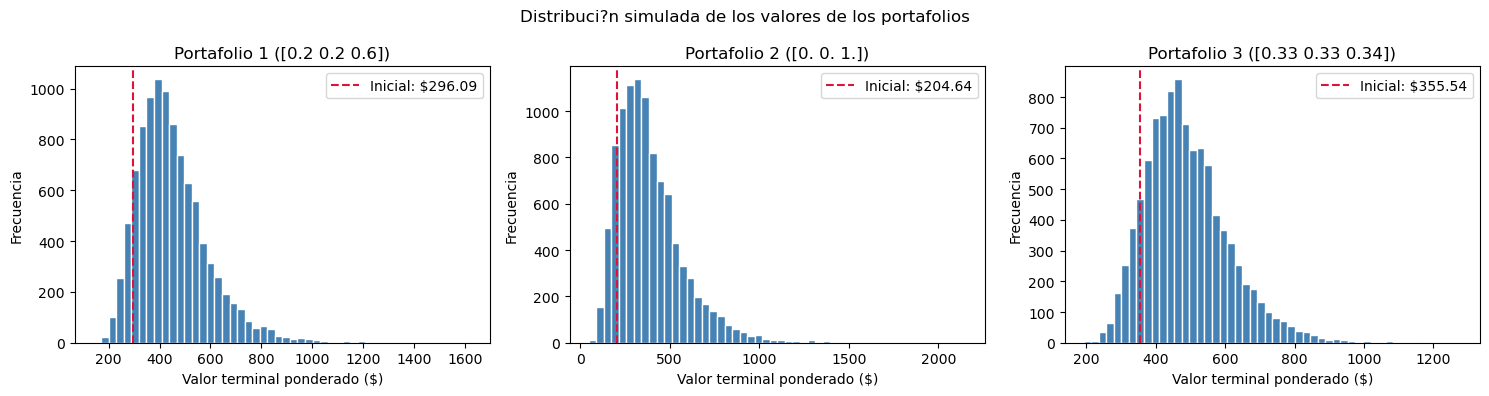

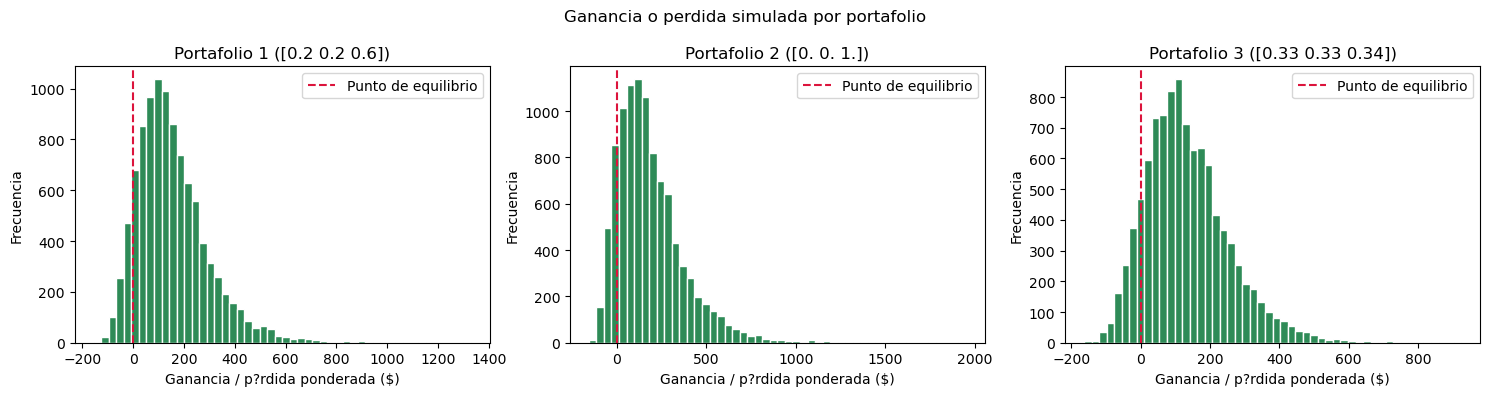

In [46]:


fig, axes = plt.subplots(1, len(Pesos), figsize=(15, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.hist(ST_portafolios[i], bins=50, color="steelblue", edgecolor="white")
    ax.axvline(S0_portafolios[i], color="crimson", linestyle="--", label=f"Inicial: ${S0_portafolios[i]:,.2f}")
    ax.set(title=f"Portafolio {i + 1} ({Pesos[i]})", xlabel="Valor terminal ponderado ($)", ylabel="Frecuencia")
    ax.legend()
fig.suptitle("Distribuci?n simulada de los valores de los portafolios")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(Pesos), figsize=(15, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.hist(resultado_portafolios[i], bins=50, color="seagreen", edgecolor="white")
    ax.axvline(0, color="crimson", linestyle="--", label="Punto de equilibrio")
    ax.set(title=f"Portafolio {i + 1} ({Pesos[i]})", xlabel="Ganancia / p?rdida ponderada ($)", ylabel="Frecuencia")
    ax.legend()
fig.suptitle("Ganancia o perdida simulada por portafolio")
fig.tight_layout()
plt.show()

---

## Análisis de riesgo de portafolios mediante VaR y CVaR

Se realizarán 10,000 simulaciones de Monte Carlo para evaluar tres estrategias de inversión. Se analizará la distribución de los valores finales, los cuartiles y las medidas de riesgo VaR y CVaR con un nivel de confianza del 95%.

### Construcción de los portafolios

Se consideran tres estrategias de inversión con un capital inicial de $100,000 MXN:

| Portafolio | Apple (AAPL) | Microsoft (MSFT) | Nvidia (NVDA) |
|:---:|:---:|:---:|:---:|
| A | 100% | 0% | 0% |
| B | 33% | 33% | 34% |
| C | 20% | 20% | 60% |

Cada estrategia permite analizar cómo cambia el comportamiento de la inversión dependiendo de la distribución del capital entre los activos.

In [59]:
# Ponderaciones de los portafolios
portafolios = {
    'A': np.array([1, 0, 0]),
    'B': np.array([0.33, 0.33, 0.34]),
    'C': np.array([0.20, 0.20, 0.60])
}

# Capital inicial
V0 = 100000

# Guardar resultados
resultados = {}

for nombre, w in portafolios.items():

    # Cantidad invertida en cada activo
    N = (w * V0) / S0_corr

    # Valor final de las 10,000 simulaciones
    VT = N @ ST_corr

    # Ganancias y pérdidas
    PnL = VT - V0

    # Pérdidas
    perdidas = V0 - VT

    resultados[nombre] = {
        'VT': VT,
        'PnL': PnL,
        'Perdidas': perdidas
    }



In [60]:
tabla_riesgo = {}

for nombre, resultado in resultados.items():

    VT = resultado['VT']
    perdidas = resultado['Perdidas']

    Q1, Q2, Q3 = np.quantile(VT, [0.25, 0.50, 0.75])

    VaR = np.quantile(perdidas, 0.95)

    CVaR = perdidas[perdidas >= VaR].mean()

    tabla_riesgo[nombre] = {
        'Media': np.mean(VT),
        'Q1': Q1,
        'Q2': Q2,
        'Q3': Q3,
        'VaR 95%': VaR,
        'CVaR 95%': CVaR,
        'Probabilidad de pérdida': np.mean(VT < V0)
    }

tabla_riesgo = pd.DataFrame(tabla_riesgo).T

display(tabla_riesgo.round(2))

,Media,Q1,Q2,Q3,VaR 95%,CVaR 95%,Probabilidad de pérdida
A,131583.26,106217.54,126850.14,152090.49,18562.81,26406.79,0.18
B,147880.98,118256.32,141043.65,170421.43,8601.02,17051.54,0.10
C,164680.67,121824.73,152970.74,193644.81,11409.37,21236.13,0.10


## Distribución del valor final y peor 5%

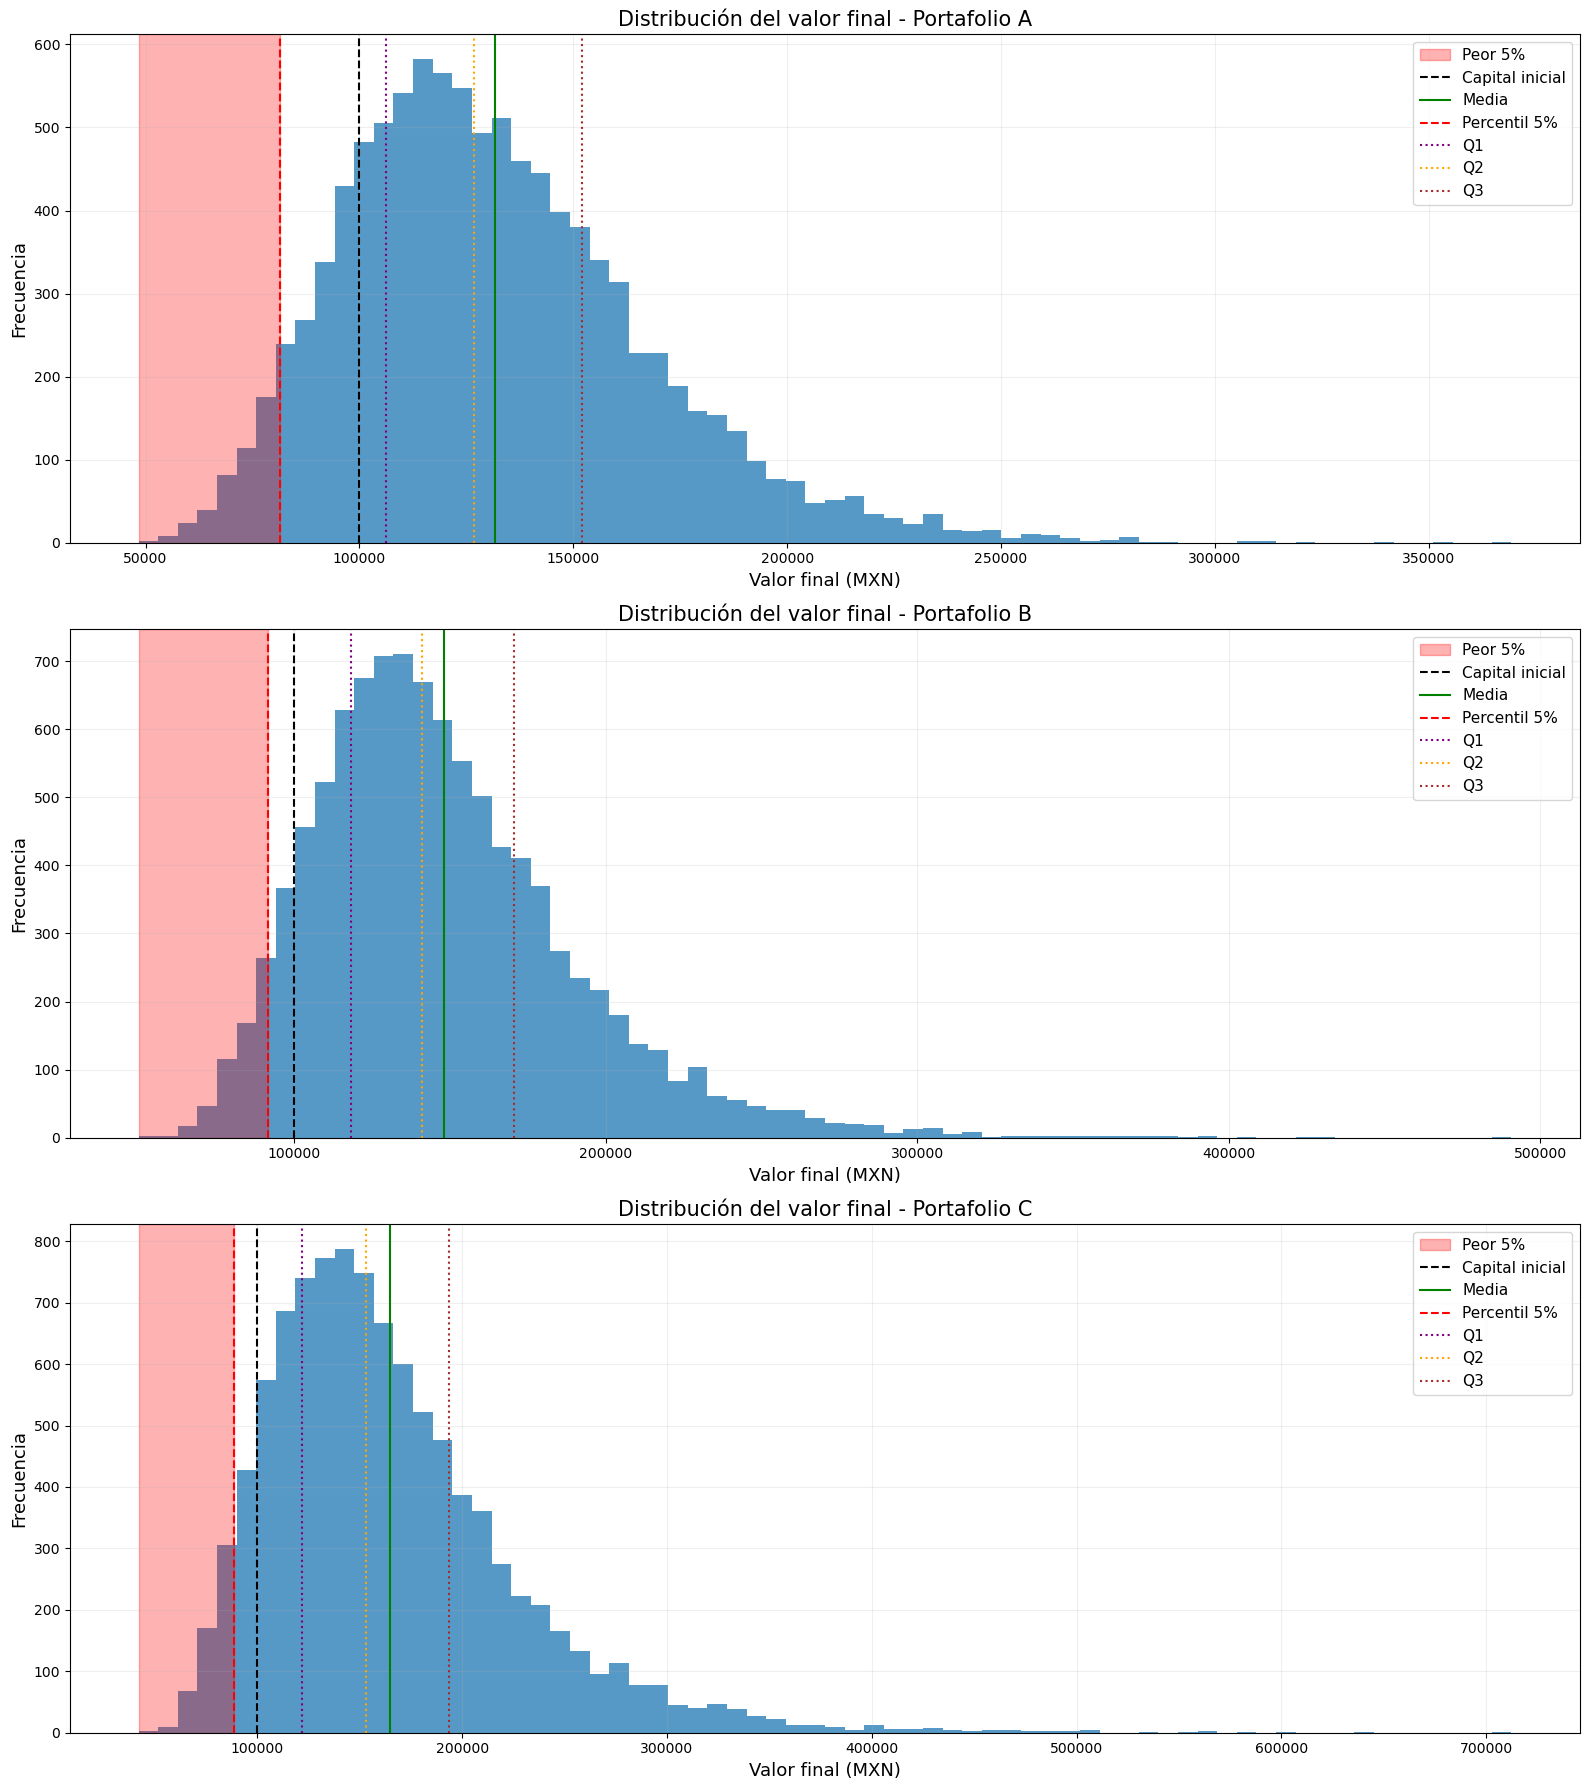

In [62]:
# Distribución del valor final y peor 5%

fig, axes = plt.subplots(3, 1, figsize=(16, 18))

for i, (nombre, resultado) in enumerate(resultados.items()):

    VT = resultado['VT']

    # Calcular media y cuartiles
    media = np.mean(VT)
    Q1, Q2, Q3 = np.quantile(VT, [0.25, 0.50, 0.75])

    # Percentil 5: límite del peor 5%
    P5 = np.quantile(VT, 0.05)

    # Histograma
    axes[i].hist(VT, bins=70, alpha=0.75)

    # Sombrear el peor 5%
    axes[i].axvspan(
        VT.min(), P5,
        color='red',
        alpha=0.30,
        label='Peor 5%'
    )

    # Líneas de referencia
    axes[i].axvline(
        V0, color='black', linestyle='--',
        label='Capital inicial'
    )

    axes[i].axvline(
        media, color='green', linestyle='-',
        label='Media'
    )

    axes[i].axvline(
        P5, color='red', linestyle='--',
        label='Percentil 5%'
    )

    axes[i].axvline(
        Q1, color='purple', linestyle=':',
        label='Q1'
    )

    axes[i].axvline(
        Q2, color='orange', linestyle=':',
        label='Q2'
    )

    axes[i].axvline(
        Q3, color='brown', linestyle=':',
        label='Q3'
    )

    axes[i].set_title(
        f'Distribución del valor final - Portafolio {nombre}',
        fontsize=15
    )

    axes[i].set_xlabel('Valor final (MXN)', fontsize=13)
    axes[i].set_ylabel('Frecuencia', fontsize=13)
    axes[i].legend(fontsize=11)
    axes[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Distribución de pérdidas, VaR y CVaR

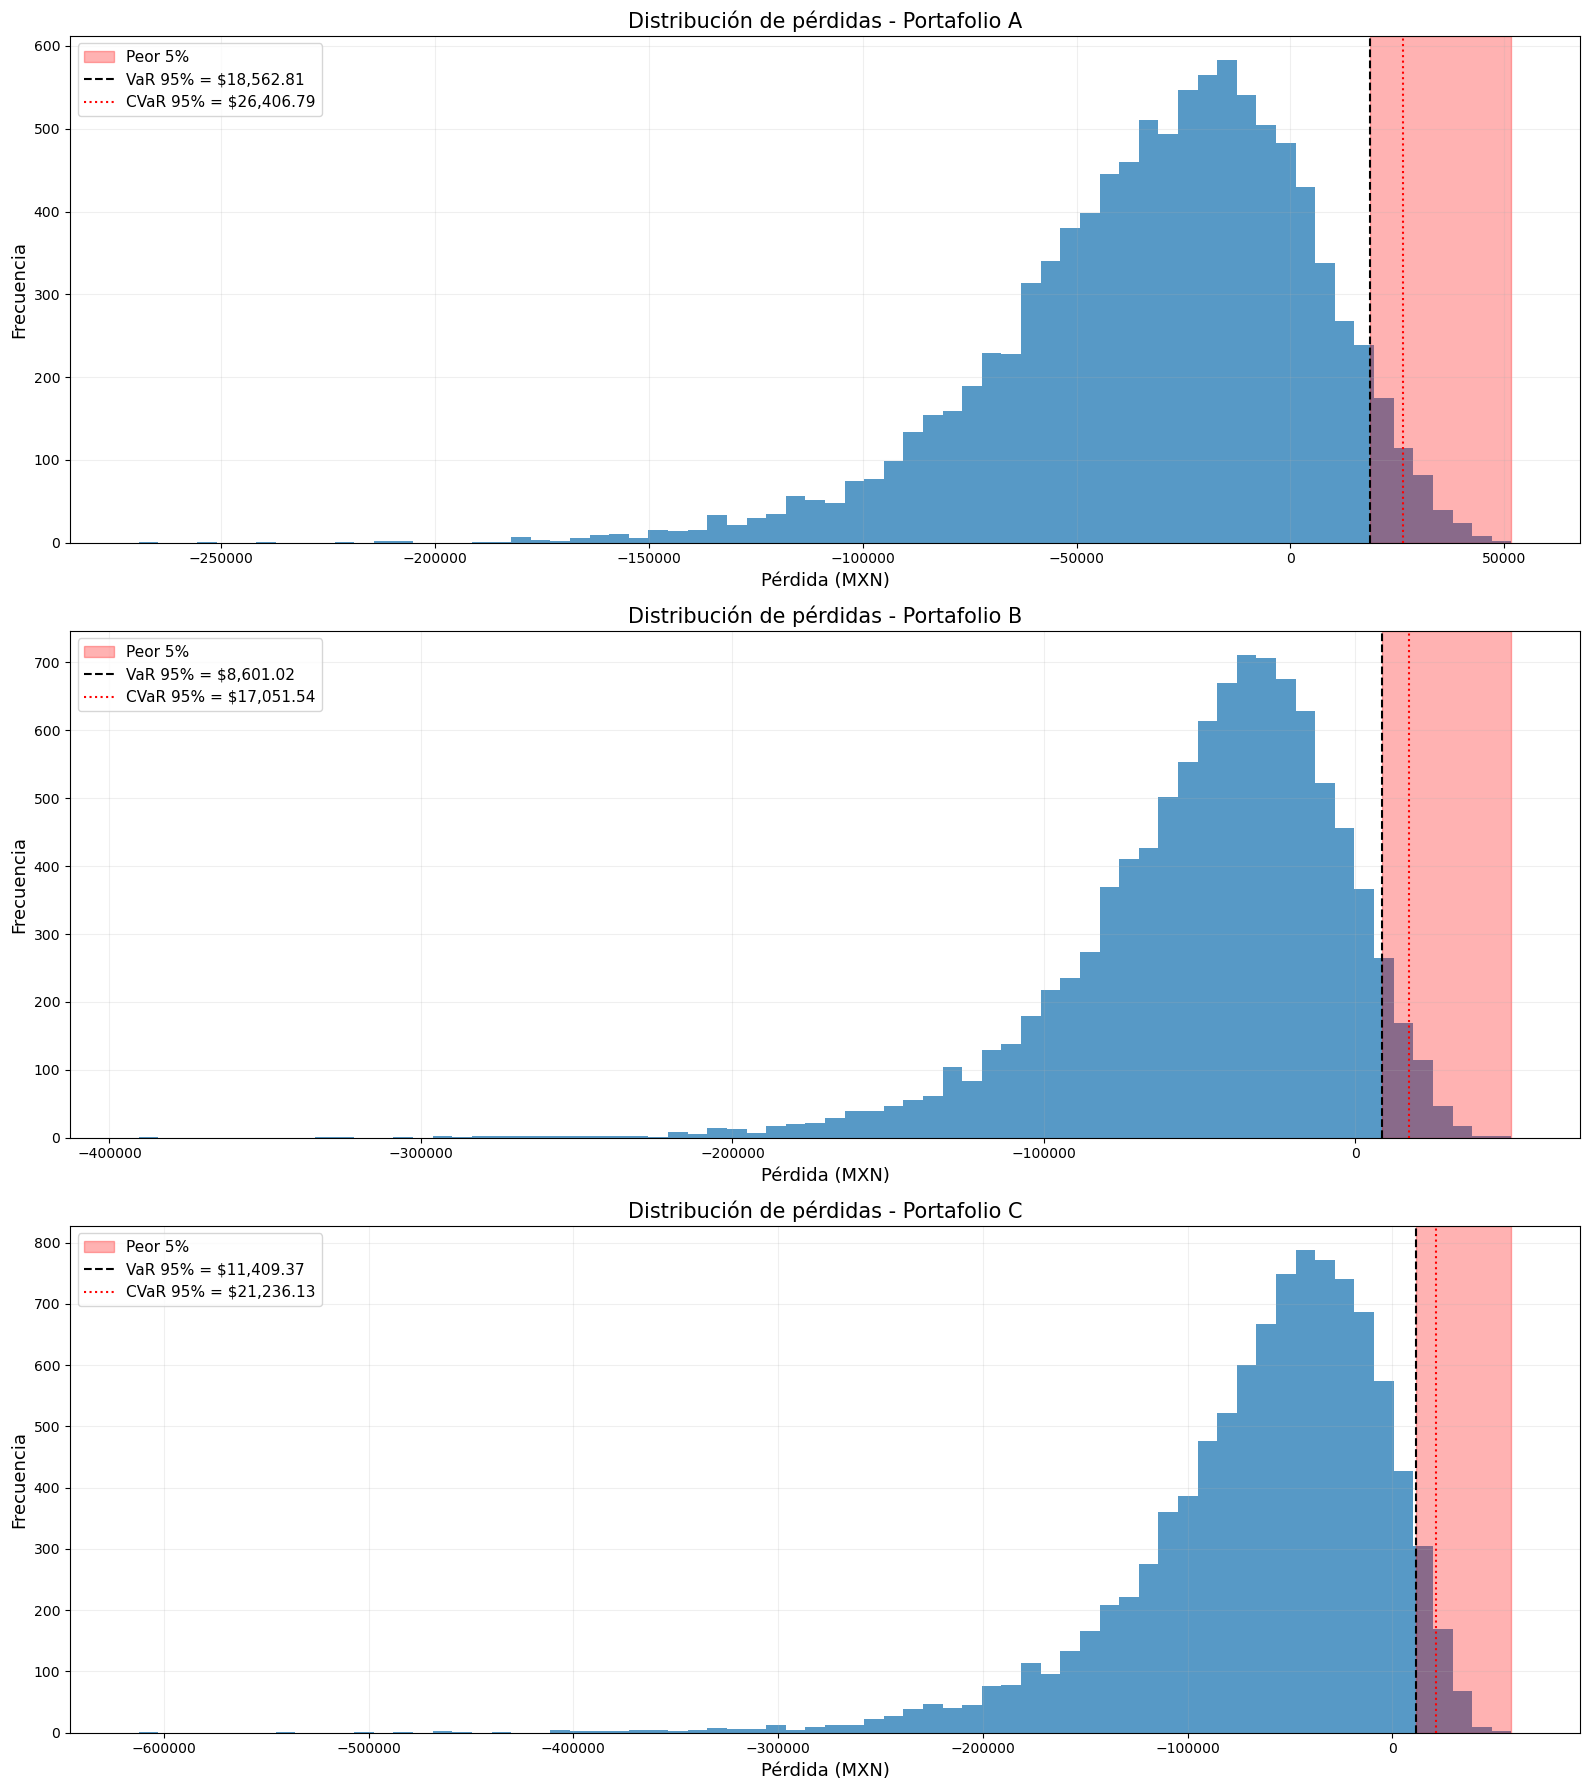

In [64]:
# Distribución de pérdidas, VaR y CVaR

fig, axes = plt.subplots(3, 1, figsize=(16, 18))

for i, (nombre, resultado) in enumerate(resultados.items()):

    # Obtener pérdidas
    VT = resultado['VT']
    perdidas = V0 - VT

    # Calcular VaR y CVaR al 95%
    VaR = np.quantile(perdidas, 0.95)
    CVaR = perdidas[perdidas >= VaR].mean()

    # Histograma
    axes[i].hist(perdidas, bins=70, alpha=0.75)

    # Sombrear el peor 5%
    axes[i].axvspan(
        VaR, perdidas.max(),
        color='red',
        alpha=0.30,
        label='Peor 5%'
    )

    # Línea del VaR
    axes[i].axvline(
        VaR,
        color='black',
        linestyle='--',
        label=f'VaR 95% = ${VaR:,.2f}'
    )

    # Línea del CVaR
    axes[i].axvline(
        CVaR,
        color='red',
        linestyle=':',
        label=f'CVaR 95% = ${CVaR:,.2f}'
    )

    axes[i].set_title(
        f'Distribución de pérdidas - Portafolio {nombre}',
        fontsize=15
    )

    axes[i].set_xlabel('Pérdida (MXN)', fontsize=13)
    axes[i].set_ylabel('Frecuencia', fontsize=13)
    axes[i].legend(fontsize=11)
    axes[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()